# Assignment 17: Implementation of a Reinforcement Learning Program using the Q-Learning Algorithm
**Aim:** Implement the Q-Learning algorithm on a 2-state, 2-action environment (states `S1`, `S2`; actions `A1`, `A2`; discount factor γ = 0.9; learning rate α = 0.1) for 5 iterations. Display the Q-table after each iteration, and derive the final Q-table and the learned policy.  
**Tools / Libraries:** `numpy`, `pandas`, `matplotlib`  
**Programming Platform / Language:** Jupyter Notebook, Python

## Theory & Task Overview

### Q-Learning
Q-Learning is a model-free, off-policy reinforcement learning algorithm that learns the quality `Q(s, a)` of taking action `a` in state `s`. After taking action `a` in state `s`, receiving reward `r` and moving to state `s'`, the Q-value is updated with:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \big[\, r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,\big]$$

* **States:** `S1`, `S2`
* **Actions:** `A1`, `A2`
* **Discount factor:** γ = 0.9
* **Learning rate:** α = 0.1
* **Initial Q-table:** all zeros
* **Transition and reward model (deterministic):**

| State, Action | Next State | Reward |
|---|---|---|
| S1, A1 | S1 | 2 |
| S1, A2 | S2 | 5 |
| S2, A1 | S1 | 1 |
| S2, A2 | S2 | 3 |

* **Iteration:** in each iteration, the Q-value of every state-action pair is updated once (in the order S1-A1, S1-A2, S2-A1, S2-A2), using the latest Q-table.
* **Policy representation:** `0 → A1`, `1 → A2`, taken as the action with the maximum Q-value in each state.

## Step 1: Import Libraries and Define the Environment

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

states = ["S1", "S2"]
actions = ["A1", "A2"]
gamma = 0.9      # discount factor
alpha = 0.1      # learning rate
num_iterations = 5

# Deterministic model: (state, action) -> (next_state, reward)
# state index: S1=0, S2=1 ; action index: A1=0, A2=1
next_state = np.array([[0, 1],    # S1: A1->S1, A2->S2
                       [0, 1]])   # S2: A1->S1, A2->S2
reward = np.array([[2, 5],        # S1: A1=2, A2=5
                   [1, 3]])       # S2: A1=1, A2=3

print("Environment defined successfully!")
print("States :", states)
print("Actions:", actions)
print("Gamma  :", gamma, "| Alpha:", alpha, "| Iterations:", num_iterations)

Environment defined successfully!
States : ['S1', 'S2']
Actions: ['A1', 'A2']
Gamma  : 0.9 | Alpha: 0.1 | Iterations: 5


---
## Step 2: Q-Learning Updates
We initialize the **Q-table with zeros** and apply the Q-learning update rule. The Q-table is displayed after each iteration.

In [2]:
# 1. Initialize Q-table with zeros
Q = np.zeros((len(states), len(actions)))
history = [Q.copy()]

print("=" * 50)
print("        Q-TABLE AFTER EACH ITERATION        ")
print("=" * 50)
print("Initial Q-table:")
print(pd.DataFrame(Q, index=states, columns=actions).round(4))

# 2. Perform Q-learning iterations
for it in range(1, num_iterations + 1):
    for s in range(len(states)):
        for a in range(len(actions)):
            s_next = next_state[s, a]
            r = reward[s, a]
            # Q(s,a) <- Q(s,a) + alpha * [r + gamma * max_a' Q(s',a') - Q(s,a)]
            td_target = r + gamma * np.max(Q[s_next])
            Q[s, a] = Q[s, a] + alpha * (td_target - Q[s, a])
    history.append(Q.copy())
    print(f"\nIteration {it}:")
    print(pd.DataFrame(Q, index=states, columns=actions).round(4))
print("=" * 50)

        Q-TABLE AFTER EACH ITERATION        
Initial Q-table:
     A1   A2
S1  0.0  0.0
S2  0.0  0.0

Iteration 1:
       A1      A2
S1  0.200  0.5000
S2  0.145  0.3131

Iteration 2:
        A1      A2
S1  0.4250  0.9782
S2  0.3185  0.6104

Iteration 3:
        A1      A2
S1  0.6705  1.4353
S2  0.5159  0.9043

Iteration 4:
        A1      A2
S1  0.9327  1.8732
S2  0.7329  1.1953

Iteration 5:
       A1      A2
S1  1.208  2.2934
S2  0.966  1.4833


---
## Step 3: Final Q-Table and Learned Policy
For each state we choose the action with the maximum Q-value. Policy encoding: **0 → A1**, **1 → A2**.

In [3]:
policy = np.argmax(Q, axis=1)

print("=" * 50)
print("          FINAL RESULTS          ")
print("=" * 50)
print("Final Q-table:")
print(pd.DataFrame(Q, index=states, columns=actions).round(4))

print("\nLearned Policy (0 -> A1, 1 -> A2):", policy)
for s in range(len(states)):
    print(f"  {states[s]} -> {actions[policy[s]]}")
print("=" * 50)

          FINAL RESULTS          
Final Q-table:
       A1      A2
S1  1.208  2.2934
S2  0.966  1.4833

Learned Policy (0 -> A1, 1 -> A2): [1 1]
  S1 -> A2
  S2 -> A2


---
## Step 4: Visualizing Q-Value Learning
We plot how each Q(s, a) value evolves over the iterations.

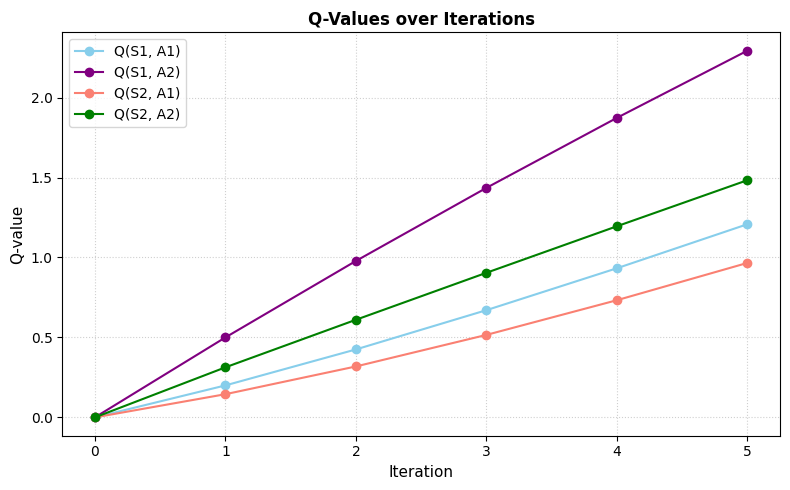

In [4]:
h = np.array(history)   # shape: (iterations + 1, states, actions)

plt.figure(figsize=(8, 5))
colors = ['skyblue', 'purple', 'salmon', 'green']
i = 0
for s in range(len(states)):
    for a in range(len(actions)):
        plt.plot(h[:, s, a], marker='o', label=f"Q({states[s]}, {actions[a]})", color=colors[i])
        i += 1
plt.title('Q-Values over Iterations', fontsize=12, fontweight='bold')
plt.xlabel('Iteration', fontsize=11)
plt.ylabel('Q-value', fontsize=11)
plt.xticks(range(num_iterations + 1))
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## Conclusion
* After 5 iterations the Q-values are still small because the learning rate is low (α = 0.1) and Q-learning moves each value only a fraction of the way toward its target on every update.
* In each state the action with the highest Q-value is **A2** (higher immediate reward and a better long-term value), so the learned policy is **[1, 1]**.
* With more iterations, the Q-values converge to the optimal values: Q(S1, A2) = 32, Q(S2, A2) = 30, Q(S1, A1) = 30.8 and Q(S2, A1) = 29.8.